# Multi-instance quantum datasets

In each task a datapoint is several quantum states (or an interaction acting on two copies), and the label lies in
the relation between them. This notebook loads the three datasets and reproduces Figs. 2 and 4.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="pkg_resources")  # harmless import warning of strawberryfields 0.23

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch
from matplotlib.ticker import MultipleLocator
from strawberryfields.backends import BaseFockState

from cv_relational_learning import fock
from cv_relational_learning.datasets import load_dataset
from cv_relational_learning.paths import FIGURES_DIR

FIGURES_DIR.mkdir(exist_ok=True)

## Loading a dataset

`load_dataset(name, cutoff, n_train, n_val, n_test)` returns train, validation and test sets. Sizes are per class,
and class 1 comes first.

In [2]:
train, val, test = load_dataset("hidden_rotation", cutoff=25, n_train=49, n_val=1, n_test=1)

x, label = train[0]
print(f"{len(train)} training pairs, datapoint shape {tuple(x.shape)}, norm {torch.linalg.norm(x):.4f}")
print("labels:", train.targets[:3].tolist(), "...", train.targets[-3:].tolist())

98 training pairs, datapoint shape (25, 25), norm 1.0000
labels: [1.0, 1.0, 1.0] ... [0.0, 0.0, 0.0]


Each state is shown by the Wigner function of its mode (strawberryfields convention, $\hbar = 2$).

In [3]:
def compute_wigner(ket, mode=0, xlim=4, num_points=200):
    # Wigner function of the reduced state of `mode` of a multi-mode ket (one array axis per mode)
    ket = np.asarray(ket)
    state = BaseFockState(ket, num_modes=ket.ndim, pure=True, cutoff_dim=ket.shape[0])
    x = np.linspace(-xlim, xlim, num_points)
    p = np.linspace(-xlim, xlim, num_points)
    W = state.wigner(mode, x, p)
    return x, p, W

## Hidden rotation (Sec. III.1)

A datapoint is a pair $|\psi\rangle \otimes R(\theta)|\psi\rangle$ of a random squeezed, displaced state. In class 1,
$\theta = 1$; in class 0, $\theta$ is random outside $[0.5, 1.5]$.

**Fig. 2**: mode 0 in blue, mode 1 in red.

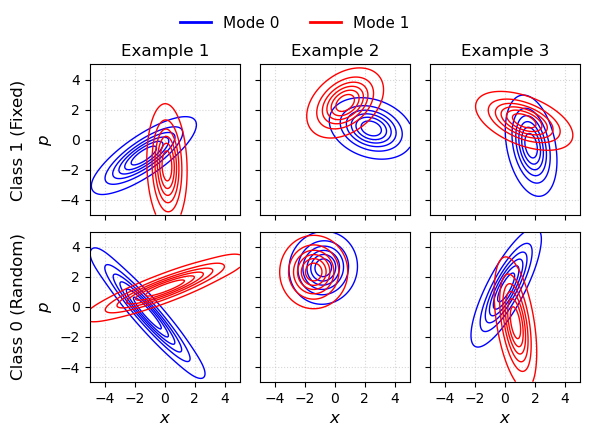

In [4]:
data_A = train.data[:49]  # class 1
data_B = train.data[49:]  # class 0


def plot_dataset_grid(n_examples=3, xlim=5):
    mode0col = "blue"
    mode1col = "red"
    fig, axes = plt.subplots(2, n_examples, figsize=(2.0 * n_examples, 4.4), sharex=True, sharey=True)
    levels = np.linspace(0.01, 5, 200)

    for col in range(n_examples):
        # top row: class 1 example, bottom row: class 0 example
        for row, ket in ((0, data_A[col]), (1, data_B[col + 5])):
            x, p, W0 = compute_wigner(ket.numpy(), 0, xlim=xlim)
            _, _, W1 = compute_wigner(ket.numpy(), 1, xlim=xlim)
            axes[row, col].contour(x, p, W0, colors=mode0col, levels=levels, linewidths=1)
            axes[row, col].contour(x, p, W1, colors=mode1col, levels=levels, linewidths=1)
        axes[0, col].set_title(f"Example {col+1}", fontsize=12)

    for ax in axes.flat:
        ax.set_aspect("equal")
        ax.tick_params(labelsize=10)
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.xaxis.set_major_locator(MultipleLocator(2))
        ax.yaxis.set_major_locator(MultipleLocator(2))

    for col in range(n_examples):
        axes[1, col].set_xlabel(r"$x$", fontsize=12)
    axes[0, 0].set_ylabel("Class 1 (Fixed)\n" + r"$p$", fontsize=12, linespacing=2)
    axes[1, 0].set_ylabel("Class 0 (Random)\n" + r"$p$", fontsize=12, linespacing=2)

    legend_elements = [
        Line2D([0], [0], color=mode0col, lw=2, label="Mode 0"),
        Line2D([0], [0], color=mode1col, lw=2, label="Mode 1"),
    ]
    fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 0.98),
               ncol=2, fontsize=11, frameon=True, facecolor="white", edgecolor="none")

    plt.tight_layout()
    fig.subplots_adjust(top=0.84, hspace=0.1)
    plt.savefig(FIGURES_DIR / "fig2_hidden_rotation_examples.pdf", dpi=300, bbox_inches="tight")
    plt.show()


plot_dataset_grid(n_examples=3)

The relative rotation, read off the mean amplitudes $\langle a\rangle$ of the two modes:

In [5]:
a = fock.annihilation(25)


def relative_rotation(x):
    # x[i, j] = amplitude of |i>|j>; (a x)[i, j] acts on mode 0, (x a^T)[i, j] on mode 1
    mean_0 = torch.vdot(x.reshape(-1), (a @ x).reshape(-1))
    mean_1 = torch.vdot(x.reshape(-1), (x @ a.T).reshape(-1))
    return torch.angle(mean_1 / mean_0).item() % (2 * np.pi)


theta_1 = np.array([relative_rotation(x) for x in data_A])
theta_0 = np.array([relative_rotation(x) for x in data_B])
print(f"class 1: relative rotation between {theta_1.min():.4f} and {theta_1.max():.4f}")
print(f"class 0: {np.sum((theta_0 > 0.5) & (theta_0 < 1.5))} of {len(theta_0)} pairs inside [0.5, 1.5]; "
      f"examples {np.round(theta_0[:5], 2)}")

class 1: relative rotation between 1.0000 and 1.0000
class 0: 0 of 49 pairs inside [0.5, 1.5]; examples [5.72 2.   2.18 0.1  0.23]


## Chirality (Sec. III.2)

A datapoint is a triplet of coherent states forming a triangle in phase space. The label is its orientation (class 1
clockwise). The third state also carries a hidden squeeze.

In [6]:
train_c, _, _ = load_dataset("chirality", cutoff=20, n_train=10, n_val=1, n_test=1)

x, label = train_c[0]
print(f"datapoint shape {tuple(x.shape)}, label {int(label)}; labels of the 20 training triplets:")
print(train_c.targets.int().tolist())

datapoint shape (20, 20, 20), label 1; labels of the 20 training triplets:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


**Fig. 4**: one triplet per class. The printed figure used a different draw of this dataset.

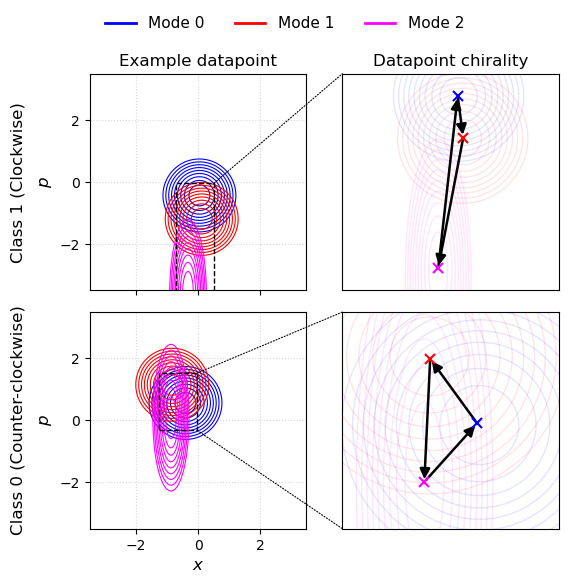

In [7]:
def plot_interleaved_triplet(n_examples=1, title=""):
    mode0col = "blue"
    mode1col = "red"
    mode2col = "magenta"

    total_columns = 2 * n_examples
    fig_width = max(3.0 * total_columns, 6.0)
    fig, axes = plt.subplots(2, total_columns, figsize=(fig_width, 6.5), sharex=False, sharey=False, squeeze=False)

    # link only the main plots (even columns)
    base_main_ax = axes[0, 0]
    for j in range(2):
        for i in range(n_examples):
            col_idx = 2 * i
            if (j, col_idx) != (0, 0):
                axes[j, col_idx].sharex(base_main_ax)
                axes[j, col_idx].sharey(base_main_ax)
    base_main_ax.set_xlim(-3.5, 3.5)
    base_main_ax.set_ylim(-3.5, 3.5)

    arrow_style = dict(arrowstyle="-|>", color="black", lw=1.8, mutation_scale=15)
    zoom_padding = 0.4

    for j in range(2):
        for i in range(n_examples):
            state_idx = 10 * j + i  # class 1 first, then class 0
            ax_main = axes[j, 2 * i]
            ax_zoom = axes[j, 2 * i + 1]

            ket = train_c.data[state_idx].numpy()
            x, p, W0 = compute_wigner(ket, mode=0, xlim=5, num_points=200)
            _, _, W1 = compute_wigner(ket, mode=1, xlim=5, num_points=200)
            _, _, W2 = compute_wigner(ket, mode=2, xlim=5, num_points=200)

            levels0 = np.linspace(W0.max() * 0.5, W0.max(), 10)
            levels1 = np.linspace(W1.max() * 0.5, W1.max(), 10)
            levels2 = np.linspace(W2.max() * 0.5, W2.max(), 10)

            # main subplot
            ax_main.contour(x, p, W0, levels=levels0, colors=mode0col, linewidths=0.8)
            ax_main.contour(x, p, W1, levels=levels1, colors=mode1col, linewidths=0.8)
            ax_main.contour(x, p, W2, levels=levels2, colors=mode2col, linewidths=0.8)

            # zoomed subplot (faint contours)
            ax_zoom.contour(x, p, W0, levels=levels0, colors=mode0col, linewidths=1, alpha=0.1)
            ax_zoom.contour(x, p, W1, levels=levels1, colors=mode1col, linewidths=1, alpha=0.1)
            ax_zoom.contour(x, p, W2, levels=levels2, colors=mode2col, linewidths=1, alpha=0.1)

            # centres = Wigner maxima, joined 0 -> 1 -> 2 -> 0
            centres = []
            for W in (W0, W1, W2):
                r, c = np.unravel_index(np.argmax(W), W.shape)
                centres.append((x[c], p[r]))
            for centre, col in zip(centres, (mode0col, mode1col, mode2col)):
                ax_zoom.plot(*centre, "x", color=col, markersize=7, markeredgewidth=1.5, zorder=5)
            for k in range(3):
                ax_zoom.annotate("", xy=centres[(k + 1) % 3], xytext=centres[k], arrowprops=arrow_style)

            # zoom box around the triangle
            x_coords = [c[0] for c in centres]
            p_coords = [c[1] for c in centres]
            z_xmin, z_xmax = min(x_coords) - zoom_padding, max(x_coords) + zoom_padding
            z_ymin, z_ymax = min(p_coords) - zoom_padding, max(p_coords) + zoom_padding
            # square view of the box (equal aspect), centred on it
            half = max(z_xmax - z_xmin, z_ymax - z_ymin) / 2
            x_mid, y_mid = (z_xmin + z_xmax) / 2, (z_ymin + z_ymax) / 2
            ax_zoom.set_xlim(x_mid - half, x_mid + half)
            ax_zoom.set_ylim(y_mid - half, y_mid + half)

            # guiding lines
            rect = plt.Rectangle((z_xmin, z_ymin), z_xmax - z_xmin, z_ymax - z_ymin, facecolor="none",
                                 edgecolor="black", linestyle="--", linewidth=1.0, alpha=1, zorder=10)
            ax_main.add_patch(rect)
            for corner_main, corner_zoom in (((z_xmax, z_ymax), (0, 1)), ((z_xmax, z_ymin), (0, 0))):
                fig.add_artist(ConnectionPatch(
                    xyA=corner_main, coordsA="data", axesA=ax_main,
                    xyB=corner_zoom, coordsB="axes fraction", axesB=ax_zoom,
                    color="black", linestyle=":", lw=0.8, alpha=1.0,
                ))

            ax_main.set_box_aspect(1)
            ax_main.set_aspect("equal", adjustable="box")
            ax_main.tick_params(labelsize=10)
            ax_main.grid(True, linestyle=":", alpha=0.5)
            ax_main.xaxis.set_major_locator(MultipleLocator(2))
            ax_main.yaxis.set_major_locator(MultipleLocator(2))

            ax_zoom.set_box_aspect(1)
            ax_zoom.set_aspect("equal")
            ax_zoom.grid(False)
            ax_zoom.set_xticks([])
            ax_zoom.set_yticks([])

    for i in range(n_examples):
        axes[0, 2 * i].set_title("Example datapoint", fontsize=12)
        axes[0, 2 * i + 1].set_title("Datapoint chirality", fontsize=12)
        axes[1, 2 * i].set_xlabel(r"$x$", fontsize=12)
        axes[0, 2 * i].tick_params(labelbottom=False)
    axes[0, 0].set_ylabel("Class 1 (Clockwise)\n" + r"$p$", fontsize=12, linespacing=2)
    axes[1, 0].set_ylabel("Class 0 (Counter-clockwise)\n" + r"$p$", fontsize=12, linespacing=2)

    legend_elements = [
        Line2D([0], [0], color=mode0col, lw=2, label="Mode 0"),
        Line2D([0], [0], color=mode1col, lw=2, label="Mode 1"),
        Line2D([0], [0], color=mode2col, lw=2, label="Mode 2"),
    ]
    fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 0.91),
               ncol=3, fontsize=11, frameon=True, facecolor="white", edgecolor="none")
    if title:
        fig.suptitle(title, fontsize=14, y=0.98, weight="bold")

    plt.tight_layout()
    fig.subplots_adjust(top=0.80, bottom=0.10, hspace=0.1)
    plt.savefig(FIGURES_DIR / "fig4_chirality_examples.pdf", dpi=300, bbox_inches="tight")
    plt.show()


plot_interleaved_triplet(1)

## Sensing (Sec. III.3)

A datapoint is a two-mode unitary $U = \big(R(\varphi)\otimes R(\varphi)\big)\big(1\otimes S(\zeta)\big)$, with a real
(class 1) or imaginary (class 0) squeezing parameter $\zeta$ and an unknown rotation $\varphi$ shared by both copies.

In [8]:
d = 20
train_s, _, _ = load_dataset("sensing", cutoff=d, n_train=3, n_val=0, n_test=0)

U, label = train_s[0]
print(f"datapoint shape {tuple(U.shape)}, label {int(label)}")
print("unitary:", torch.allclose(U.conj().T @ U, torch.eye(d * d, dtype=U.dtype), atol=1e-10))

datapoint shape (400, 400), label 1
unitary: True


A squeezed probe on copy 0 and vacuum on copy 1, sent through $U$. Panel titles give the SWAP-test value of the
two outputs.

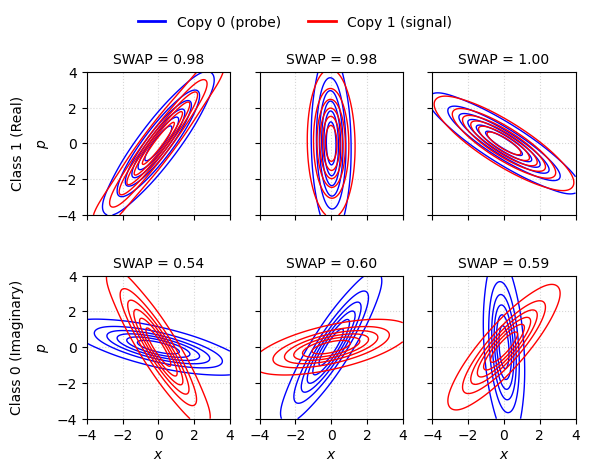

In [9]:
s = 0.75  # probe squeezing on copy 0
vacuum = fock.fock_state(0, d)
probe = torch.kron(fock.squeezing(torch.tensor(s, dtype=torch.float64), d) @ vacuum, vacuum)
swap = fock.swap_operator(d)

mode0col, mode1col = "blue", "red"
levels = np.linspace(0.01, 5, 200)
fig, axes = plt.subplots(2, 3, figsize=(6.0, 4.8), sharex=True, sharey=True)
for row, label in ((0, 1), (1, 0)):
    for col in range(3):
        U, _ = train_s[col if label == 1 else 3 + col]
        out = U @ probe
        ket = out.reshape(d, d).numpy()
        x, p, W0 = compute_wigner(ket, 0, xlim=4)
        _, _, W1 = compute_wigner(ket, 1, xlim=4)
        ax = axes[row, col]
        ax.contour(x, p, W0, colors=mode0col, levels=levels, linewidths=1)
        ax.contour(x, p, W1, colors=mode1col, levels=levels, linewidths=1)
        ax.set_title(f"SWAP = {fock.expectation(out, swap).real:.2f}", fontsize=10)
        ax.set_aspect("equal")
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.xaxis.set_major_locator(MultipleLocator(2))
        ax.yaxis.set_major_locator(MultipleLocator(2))
for col in range(3):
    axes[1, col].set_xlabel(r"$x$")
axes[0, 0].set_ylabel("Class 1 (Real)\n" + r"$p$", linespacing=2)
axes[1, 0].set_ylabel("Class 0 (Imaginary)\n" + r"$p$", linespacing=2)
fig.legend(handles=[Line2D([0], [0], color=mode0col, lw=2, label="Copy 0 (probe)"),
                    Line2D([0], [0], color=mode1col, lw=2, label="Copy 1 (signal)")],
           loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=2, frameon=False)
plt.tight_layout()
fig.subplots_adjust(top=0.84, hspace=0.3)
plt.show()